Cài đặt thư viện

In [2]:
pip install gymnasium stable-baselines3[extra] numpy matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


Import thư viện

In [3]:
import numpy as np
import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt
from stable_baselines3 import PPO # Proximal Policy Optimization
from stable_baselines3.common.env_checker import check_env

print("Thư viện đã được load thành công!")

Thư viện đã được load thành công!


In [5]:
class VideoRoutingEnv(gym.Env):
    """
    Môi trường mô phỏng Định tuyến Video cho 2 đường truyền (Link 1 và Link 2).
    """
    metadata = {"render_modes": ["human"]}

    def __init__(self):
        super(VideoRoutingEnv, self).__init__()
        
        self.max_steps = 200
        self.current_step = 0
        
        # Action Space: 0 = Đi Link 1, 1 = Đi Link 2
        self.action_space = spaces.Discrete(2)
        
        # Observation Space (State):[delay_1, loss_1, delay_2, loss_2]
        # Giới hạn: Delay từ 0->500ms, Loss từ 0->100%
        self.observation_space = spaces.Box(
            low=np.array([0.0, 0.0, 0.0, 0.0], dtype=np.float32),
            high=np.array([500.0, 100.0, 500.0, 100.0], dtype=np.float32),
            dtype=np.float32
        )

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_step = 0
        
        # Khởi tạo trạng thái ban đầu: 2 đường đều rảnh rỗi (Delay ~20ms, Loss ~0%)
        self.state = np.array([20.0, 0.0, 25.0, 0.0], dtype=np.float32)
        return self.state, {}

    def step(self, action):
        self.current_step += 1
        
        # 1. MÔ PHỎNG SỰ THAY ĐỔI MẠNG (Network Dynamics)
        # Kịch bản Tắc nghẽn: Từ step 50 đến 100, Link 1 bị quá tải đột ngột
        if 50 < self.current_step < 100:
            delay_1 = np.random.uniform(200.0, 400.0) # Delay vọt lên rất cao
            loss_1 = np.random.uniform(5.0, 15.0)     # Mất gói tin
            delay_2 = np.random.uniform(20.0, 30.0)   # Link 2 vẫn rảnh
            loss_2 = 0.0
        else:
            # Mạng bình thường
            delay_1 = np.random.uniform(15.0, 25.0)
            loss_1 = 0.0
            delay_2 = np.random.uniform(20.0, 30.0)
            loss_2 = 0.0
            
        self.state = np.array([delay_1, loss_1, delay_2, loss_2], dtype=np.float32)
        
        # 2. TÍNH TOÁN REWARD (MOS Score) DỰA VÀO ACTION CỦA AGENT
        if action == 0: # Chọn Link 1
            agent_delay = delay_1
            agent_loss = loss_1
        else:           # Chọn Link 2
            agent_delay = delay_2
            agent_loss = loss_2
            
        # Công thức tính điểm MOS (Giả lập) từ 1.0 (Tệ) đến 5.0 (Tuyệt vời)
        # Bạn có thể điều chỉnh công thức này cho chuẩn hơn với E-model thực tế
        mos_score = 5.0 - (agent_delay / 100.0) - (agent_loss * 0.2)
        mos_score = np.clip(mos_score, 1.0, 5.0) # Ép MOS không được vượt ra khỏi 1-5
        
        reward = mos_score
        
        # 3. ĐIỀU KIỆN KẾT THÚC
        terminated = False
        truncated = self.current_step >= self.max_steps
        
        info = {
            "chosen_delay": agent_delay,
            "mos_score": mos_score
        }
        
        return self.state, reward, terminated, truncated, info

# Kiểm tra xem code Env viết có đúng chuẩn của Gymnasium chưa
env = VideoRoutingEnv()
check_env(env)
print("Môi trường đã vượt qua bài kiểm tra chuẩn hóa!")

Môi trường đã vượt qua bài kiểm tra chuẩn hóa!


In [6]:
# Tạo môi trường
env = VideoRoutingEnv()

# Khởi tạo thuật toán PPO
model = PPO("MlpPolicy", env, verbose=0, learning_rate=0.001)

print("Bắt đầu huấn luyện...")
# Huấn luyện trong 10,000 bước
model.learn(total_timesteps=10000)
print("Huấn luyện hoàn tất!")

Bắt đầu huấn luyện...
Huấn luyện hoàn tất!


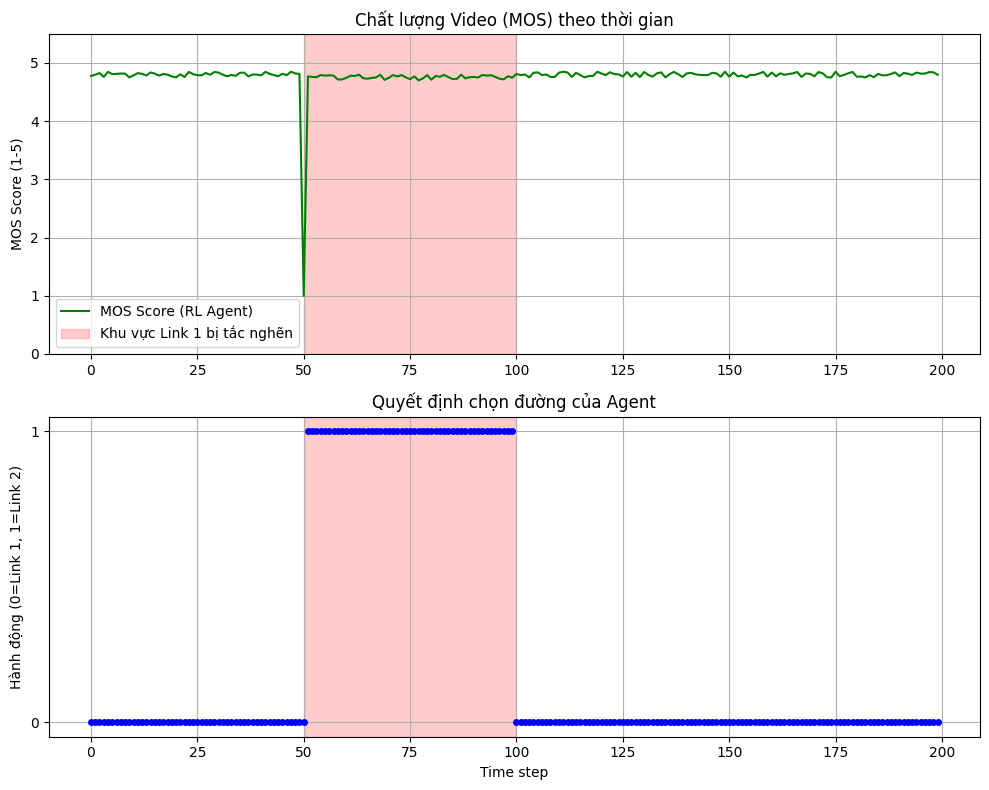

In [7]:
# Reset môi trường để chạy thử
obs, info = env.reset()

mos_history =[]
action_history =[]

for i in range(200):
    # Agent dùng "bộ não" đã học để ra quyết định
    action, _states = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = env.step(action)
    
    mos_history.append(info['mos_score'])
    action_history.append(action)

# --------- VẼ BIỂU ĐỒ BẰNG MATPLOTLIB ---------
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

# Biểu đồ 1: Điểm MOS theo thời gian
ax1.plot(mos_history, color='green', label='MOS Score (RL Agent)')
ax1.axvspan(50, 100, color='red', alpha=0.2, label='Khu vực Link 1 bị tắc nghẽn')
ax1.set_title("Chất lượng Video (MOS) theo thời gian")
ax1.set_ylabel("MOS Score (1-5)")
ax1.set_ylim(0, 5.5)
ax1.legend()
ax1.grid()

# Biểu đồ 2: Hành động của Agent
ax2.plot(action_history, color='blue', marker='o', linestyle='None', markersize=4)
ax2.axvspan(50, 100, color='red', alpha=0.2)
ax2.set_title("Quyết định chọn đường của Agent")
ax2.set_ylabel("Hành động (0=Link 1, 1=Link 2)")
ax2.set_xlabel("Time step")
ax2.set_yticks([0, 1])
ax2.grid()

plt.tight_layout()
plt.show()